# CEE 902 · Flood Prediction with K-Nearest Neighbors

**Author:** Samuel Asiedu

This notebook uses scikit-learn to predict flooding from **distance to a waterbody** and **relative elevation**. The emphasis is on sound modeling decisions:

1. Split the data into training, validation, and test sets before any modeling.
2. Apply min-max normalization using training statistics only.
3. Explore how the number of neighbors $k$ shapes the decision boundary.
4. Select $k$ with validation accuracy.
5. Evaluate the frozen model once on the test set, using accuracy, precision, recall, and F1.

## 1. Load the data

The data file is expected at `data/flood_sites.csv`. Each row is a **synthetic site** under a common reference flood scenario.

| Column | Meaning |
|---|---|
| `site_id` | Identifier, excluded from the predictors |
| `distance_to_water_m` | Distance to the nearest waterbody (m) |
| `relative_elevation_m` | Height above a local waterbody reference level (m) |
| `flooded` | 1 = flooded, 0 = did not flood |

In [1]:
# Uncomment if packages are missing:
# %pip install numpy pandas matplotlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler

DATA_FILE = "data/flood_sites.csv"
FEATURES = ["distance_to_water_m", "relative_elevation_m"]
TARGET = "flooded"
RANDOM_SEED = 42

# Shared plot settings: axis limits in physical units and the style of each class.
DISTANCE_LIMITS = (0, 2400)     # m
ELEVATION_LIMITS = (0, 24)      # m
CLASS_STYLES = {0: ("Not flooded", "steelblue", "o"),
                1: ("Flooded", "tomato", "^")}

data = pd.read_csv(DATA_FILE)
data.head()

,site_id,distance_to_water_m,relative_elevation_m,flooded
0,S0001,483.6,0.98,1
1,S0002,2184.0,0.84,1
2,S0003,1910.7,18.71,0
3,S0004,1420.0,5.58,1
4,S0005,341.5,5.38,1


## 2. Split before developing the model

The data are divided into **70% training, 15% validation, and 15% test**.

- **Training** supplies the labeled neighbors and the normalization parameters.
- **Validation** is used to compare values of $k$ and select one.
- **Test** evaluates the selected procedure once, after all decisions are complete.

The test set (15%) is reserved first. A validation set of the same size is then taken from the remaining 85%. Stratification preserves the class proportions in every subset, and a fixed random seed keeps the comparison reproducible.

In [2]:
X = data[FEATURES]
y = data[TARGET]

# Development set = training + validation. The test set is not used until Section 6.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_SEED)

# Reserve the same number of validation sites as test sites (15% of all sites).
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=len(X_test), stratify=y_dev, random_state=RANDOM_SEED)

print(f"Training: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")

Training: 560, validation: 120, test: 120


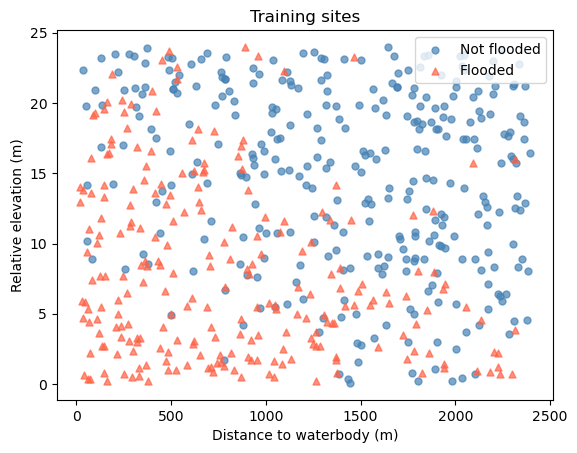

In [3]:
def plot_sites(X_sites, y_sites, size=25, **scatter_kwargs):
    # Scatter the sites in physical units, with one color and marker per class.
    for label, (name, color, marker) in CLASS_STYLES.items():
        sites = X_sites[y_sites == label]
        plt.scatter(sites[FEATURES[0]], sites[FEATURES[1]], c=color, marker=marker,
                    s=size, label=name, **scatter_kwargs)
    plt.xlabel("Distance to waterbody (m)")
    plt.ylabel("Relative elevation (m)")


plot_sites(X_train, y_train, alpha=0.7)
plt.title("Training sites")
plt.legend()
plt.show()

## 3. Why normalize? Inspect the five nearest neighbors

Before normalizing, a model with $k = 5$ is used to find the neighbors of a hypothetical site located **700 m from water at 8 m relative elevation**. The outlined points are the five selected training sites, and lines connect them to the query site.

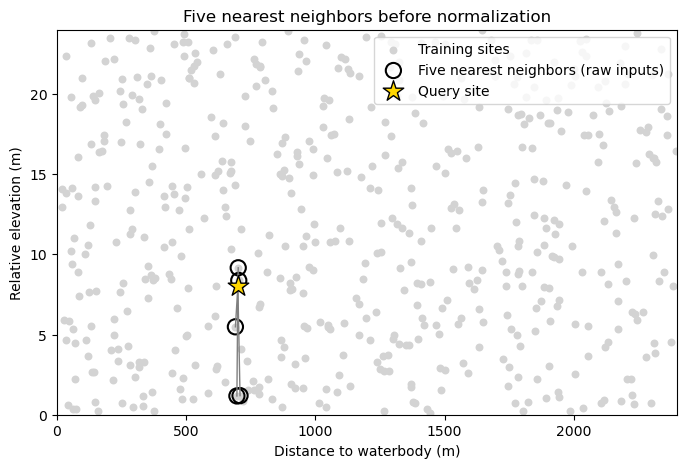

,distance_to_water_m,relative_elevation_m,distance_difference_m,elevation_difference_m,raw_euclidean_distance
781,701.4,9.16,1.4,1.16,1.82
132,703.5,8.37,3.5,0.37,3.52
166,696.3,1.17,3.7,6.83,7.77
359,690.5,5.48,9.5,2.52,9.83
652,708.4,1.19,8.4,6.81,10.81


In [4]:
QUERY_DISTANCE_M, QUERY_ELEVATION_M = 700, 8
query = pd.DataFrame([[QUERY_DISTANCE_M, QUERY_ELEVATION_M]], columns=FEATURES)

raw_knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
distances, positions = raw_knn.kneighbors(query)
neighbors = X_train.iloc[positions[0]]

plt.figure(figsize=(8, 5))
plt.scatter(X_train[FEATURES[0]], X_train[FEATURES[1]],
            c="lightgray", s=22, label="Training sites")
plt.scatter(neighbors[FEATURES[0]], neighbors[FEATURES[1]],
            facecolors="none", edgecolors="black", s=120, linewidths=1.5,
            label="Five nearest neighbors (raw inputs)")
plt.scatter(QUERY_DISTANCE_M, QUERY_ELEVATION_M, marker="*", c="gold", edgecolors="black",
            s=240, zorder=5, label="Query site")
for _, site in neighbors.iterrows():
    plt.plot([QUERY_DISTANCE_M, site[FEATURES[0]]], [QUERY_ELEVATION_M, site[FEATURES[1]]],
             color="gray", linewidth=1)
plt.xlim(DISTANCE_LIMITS)
plt.ylim(ELEVATION_LIMITS)
plt.xlabel("Distance to waterbody (m)")
plt.ylabel("Relative elevation (m)")
plt.title("Five nearest neighbors before normalization")
plt.legend(loc="upper right")
plt.show()

neighbor_details = neighbors.copy()
neighbor_details["distance_difference_m"] = (neighbors[FEATURES[0]] - QUERY_DISTANCE_M).abs()
neighbor_details["elevation_difference_m"] = (neighbors[FEATURES[1]] - QUERY_ELEVATION_M).abs()
neighbor_details["raw_euclidean_distance"] = distances[0]
neighbor_details.round(2)

**Q1. Why were these five points picked as the nearest neighbors? Does one variable dominate the selection?**

The five neighbors lie in a narrow vertical band around 700 m. Their horizontal differences from the query are all below 10 m, whereas their elevation differences reach about 6.8 m, which is more than a quarter of the full elevation range. Distance to water spans roughly 0 to 2,400 m and relative elevation only 0 to 24 m, so in raw units a 10 m horizontal offset counts as much as a 10 m elevation offset, even though the latter is a very large change in elevation. Distance to water therefore dominates the Euclidean distance, and elevation has almost no influence on which neighbors are chosen. The features need to be brought to a comparable scale.

### Apply min-max normalization

KNN computes distances from the numerical differences in each feature. Without normalization, the feature with the larger numerical range dominates the neighbor selection, even though both variables here are measured in meters.

For each predictor:

$$x_{\text{normalized}} = \frac{x - x_{\min,\text{training}}}{x_{\max,\text{training}} - x_{\min,\text{training}}}$$

**Fitting** the scaler means computing and storing each predictor's training minimum and maximum. **Transforming** means applying the formula with those stored values. The training minimum and maximum are reused for the validation observations, so no information from the validation set leaks into the model.

Training values map to $[0, 1]$. New observations outside the training range can map outside $[0, 1]$. Note that comparable ranges do not imply equal physical importance.

In [5]:
scaler = MinMaxScaler()
X_train_norm = scaler.fit_transform(X_train)     # learn min/max from training data only
X_val_norm = scaler.transform(X_val)             # reuse the training min/max

pd.DataFrame({"training_min": scaler.data_min_, "training_max": scaler.data_max_,
              "normalized_min": X_train_norm.min(axis=0),
              "normalized_max": X_train_norm.max(axis=0)}, index=FEATURES)

,training_min,training_max,normalized_min,normalized_max
distance_to_water_m,17.60,2396.50,0.0,1.0
relative_elevation_m,0.08,23.99,0.0,1.0


### Compare raw and normalized inputs

The same $k$ and the same split are used for both models, so the comparison isolates the effect of normalization.

In [6]:
COMPARISON_K = 5

raw_model = KNeighborsClassifier(n_neighbors=COMPARISON_K).fit(X_train, y_train)
normalized_model = KNeighborsClassifier(n_neighbors=COMPARISON_K).fit(X_train_norm, y_train)

raw_accuracy = accuracy_score(y_val, raw_model.predict(X_val))
normalized_accuracy = accuracy_score(y_val, normalized_model.predict(X_val_norm))
print("Raw validation accuracy:", round(raw_accuracy, 3))
print("Normalized validation accuracy:", round(normalized_accuracy, 3))

Raw validation accuracy: 0.7
Normalized validation accuracy: 0.733


## 4. Explore the decision boundary

The background shows the predicted class and the points show the training labels. The plot does not show flood depth or prediction confidence. The model works with normalized distances, while the axes display physical units.

Change `BOUNDARY_K` to **1, 5, 15, and 35** and rerun the cell to see how the boundary responds.

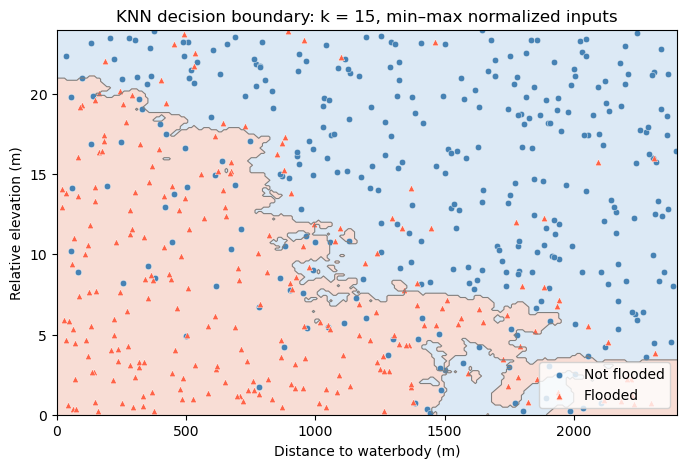

In [7]:
BOUNDARY_K = 15      # try 1, 5, 15, and 35
model = KNeighborsClassifier(n_neighbors=BOUNDARY_K).fit(X_train_norm, y_train)

# Predict the class on a regular grid that covers the plotting area.
distance_grid, elevation_grid = np.meshgrid(
    np.linspace(*DISTANCE_LIMITS, 250), np.linspace(*ELEVATION_LIMITS, 180))
grid = pd.DataFrame({FEATURES[0]: distance_grid.ravel(),
                     FEATURES[1]: elevation_grid.ravel()})
grid_predictions = model.predict(scaler.transform(grid)).reshape(distance_grid.shape)

plt.figure(figsize=(8, 5))
plt.contourf(distance_grid, elevation_grid, grid_predictions,
             levels=[-0.5, 0.5, 1.5], colors=["#dce9f5", "#f8ddd5"])
plt.contour(distance_grid, elevation_grid, grid_predictions,
            levels=[0.5], colors="gray", linewidths=0.8)
plot_sites(X_train, y_train, size=22, edgecolors="white", linewidths=0.3)
plt.xlim(DISTANCE_LIMITS)
plt.ylim(ELEVATION_LIMITS)
plt.title(f"KNN decision boundary: k = {BOUNDARY_K}, min–max normalized inputs")
plt.legend()
plt.show()

**Q2. How does the decision boundary change with increasing $k$, and what does this imply about the bias-variance tradeoff?**

| $k$ | Boundary observations |
|---|---|
| 1 | Highly irregular. Every training site is its own nearest neighbor, so the boundary wraps around individual points and creates many small isolated islands. Training accuracy is 100%, which indicates overfitting. |
| 5 | Still jagged, but the smallest islands merge or disappear because a single unusual site can be outvoted. |
| 15 | Noticeably smoother. The general pattern is clear (flooding at low elevation and close to water), with only a few irregular pockets remaining. |
| 35 | Smoothest of the four. Local detail is averaged out, and small genuine features of the boundary may be lost. |

**Bias-variance explanation.** A small $k$ gives a flexible model with **low bias and high variance**: the boundary follows the noise in the particular training sample and would change considerably with a different sample. Increasing $k$ averages over more neighbors, which **lowers variance but raises bias**, because the prediction at a point is increasingly influenced by sites that are farther away. In the limit where $k$ approaches the training-set size, the model predicts the majority class everywhere. The best $k$ balances the two effects and must be chosen with data that were not used for fitting.

## 5. Select $k$ using validation accuracy

Accuracy is the fraction of sites classified correctly. Each candidate $k$ is fitted on the training data and scored on the same validation set.

,k,validation_accuracy
0,1,0.750
1,3,0.700
2,5,0.733
3,9,0.750
4,15,0.708
5,25,0.742
6,35,0.758
7,51,0.767
8,101,0.767
9,201,0.758


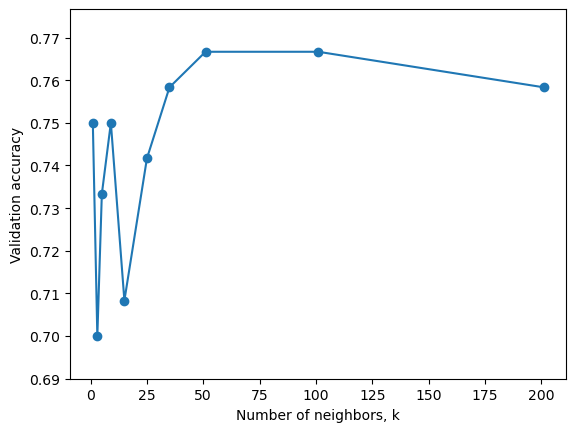

Highest validation accuracy: k = 51


In [8]:
K_VALUES = [1, 3, 5, 9, 15, 25, 35, 51, 101, 201]

validation_accuracies = []
for k in K_VALUES:
    candidate = KNeighborsClassifier(n_neighbors=k).fit(X_train_norm, y_train)
    validation_accuracies.append(accuracy_score(y_val, candidate.predict(X_val_norm)))

results = pd.DataFrame({"k": K_VALUES, "validation_accuracy": validation_accuracies})
display(results.round(3))

plt.plot(K_VALUES, validation_accuracies, "o-")
plt.xlabel("Number of neighbors, k")
plt.ylabel("Validation accuracy")
# Pad the observed range so that small differences remain visible.
padding = max(0.01, 0.15 * (max(validation_accuracies) - min(validation_accuracies)))
plt.ylim(max(0, min(validation_accuracies) - padding),
         min(1, max(validation_accuracies) + padding))
plt.show()

# For exact ties, idxmax selects the first (smallest) candidate.
best_k = int(results.loc[results["validation_accuracy"].idxmax(), "k"])
print(f"Highest validation accuracy: k = {best_k}")

**Q3. Which $k$ should be selected based on validation accuracy?**

$k = 51$ and $k = 101$ tie for the highest validation accuracy, 0.767 (92 of 120 sites correct). I select **$k = 51$**, the first of the tied candidates, which is also what `idxmax` returns. It keeps the neighborhood more local than $k = 101$ while giving the same validation performance.

The differences between candidates are small. One validation site corresponds to 0.008 in accuracy, and the standard error of an accuracy near 0.75 with 120 sites is about 0.04, so the accuracies from 0.70 to 0.77 are not clearly distinguishable. The choice of $k$ is therefore reasonable but not sharply determined by these data.

## 6. Freeze the choice, refit, and test

With $k$ selected, the model is refitted on all training and validation observations (the 85% development set). New normalization parameters are learned from this development set. This is appropriate because selection is complete and the test observations remain held out.

In [9]:
selected_k = best_k

final_scaler = MinMaxScaler()
X_dev_norm = final_scaler.fit_transform(X_dev)
final_model = KNeighborsClassifier(n_neighbors=selected_k).fit(X_dev_norm, y_dev)
print(f"Final model: k = {selected_k}, fitted on {len(X_dev)} development sites.")

Final model: k = 51, fitted on 680 development sites.


### Evaluate the test set once

The test set is used a single time. Changing $k$ after seeing the test result would turn the test set into a second validation set, and the reported accuracy would no longer be an independent estimate.

In [10]:
X_test_norm = final_scaler.transform(X_test)
test_predictions = final_model.predict(X_test_norm)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Correct predictions: {(test_predictions == y_test).sum()} of {len(y_test)}")

Test accuracy: 0.725
Correct predictions: 87 of 120


**Q4. Why might test and validation accuracy differ? Why report the test result even if it is disappointing?**

Test accuracy (0.725) is lower than validation accuracy (0.767) for two reasons. First, each estimate comes from only 120 sites, so sampling variability alone is about ±0.04 (one standard error), and the gap of 0.042 corresponds to just five sites. Second, the validation accuracy is optimistically biased because $k$ was chosen as the best of ten candidates on that same set, whereas the test set played no part in any decision.

The test result must be reported as it is because it is the only unbiased estimate of how the selected procedure performs on new sites. Discarding it, or retuning until it improves, would overstate the reliability of the model to anyone who uses it.

## 7. Accuracy does not tell the whole story

The same frozen model is examined with three further metrics, and compared with a baseline that always predicts the majority class.

- **Precision:** of the sites predicted to flood, the fraction that actually flooded.
- **Recall:** of the sites that actually flooded, the fraction that were identified.
- **F1:** the harmonic mean of precision and recall.

A missed flood and an unnecessary warning can have very different consequences, and accuracy treats them as equal.

,accuracy,precision,recall,f1
model,,,,
Majority baseline,0.575,0.000,0.000,0.000
Selected KNN,0.725,0.705,0.608,0.653


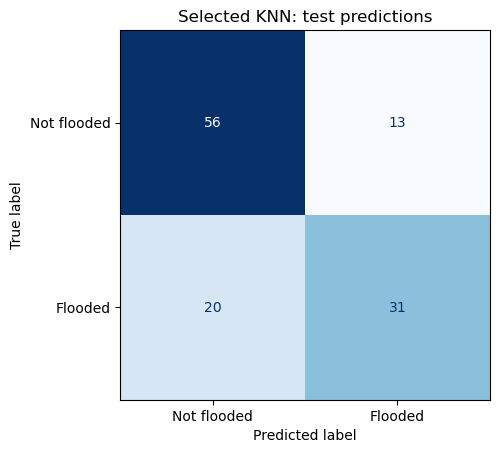

Missed floods: 20; unnecessary warnings: 13


In [11]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_dev_norm, y_dev)
baseline_predictions = baseline.predict(X_test_norm)

metric_rows = []
for name, predictions in [("Majority baseline", baseline_predictions),
                          ("Selected KNN", test_predictions)]:
    metric_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0)})
display(pd.DataFrame(metric_rows).set_index("model").round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1],
    display_labels=["Not flooded", "Flooded"], cmap="Blues", colorbar=False)
plt.title("Selected KNN: test predictions")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
print(f"Missed floods: {fn}; unnecessary warnings: {fp}")

**Q5. How many floods did KNN miss, and which metric addresses that concern?**

The model missed **20** of the 51 flooded test sites (false negatives) and identified 31. **Recall** measures this directly: 31/51 = 0.608, so about 39% of the actual floods were not detected. The model also issued 13 unnecessary warnings, which gives a precision of 31/44 = 0.705.

**Q6. If missing floods is especially costly, would accuracy alone be sufficient for model selection?**

No. Accuracy weights a missed flood and a false alarm equally, so a model can reach an acceptable accuracy (0.725 here) while missing a large share of the floods. If missed floods are the costlier error, model selection should use a metric that reflects it, such as recall or an $F_\beta$ score with $\beta > 1$, possibly subject to a minimum acceptable precision. A practical option is to lower the decision threshold on the neighbor vote fraction (`predict_proba`) below 0.5 so that more sites are flagged. Any such choice of metric, threshold, or $k$ must be made on the validation data and then confirmed on fresh test data, because the present test set has already been used and tuning against it would bias the result.

## 8. Consistency checks

The checks below confirm the 70/15/15 split, the absence of overlap between subsets, and that each scaler was fitted on the intended data.

In [ ]:
assert (len(X_train), len(X_val), len(X_test)) == (560, 120, 120)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)
assert np.allclose(scaler.data_min_, X_train.min())
assert np.allclose(scaler.data_max_, X_train.max())
assert np.allclose(final_scaler.data_min_, X_dev.min())
assert np.allclose(final_scaler.data_max_, X_dev.max())
print("Verified the 70/15/15 split and the normalization parameters.")

## References

- scikit-learn developers. *Nearest Neighbors.* scikit-learn User Guide. https://scikit-learn.org/stable/modules/neighbors.html
- scikit-learn developers. *MinMaxScaler.* scikit-learn API Reference. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html
- scikit-learn developers. *Common pitfalls and recommended practices* (data leakage). https://scikit-learn.org/stable/common_pitfalls.html